# 1.1 Exploración de modelos para P1 (versión final)

P1: ¿cuántos viajes se iniciarán en una estación en la siguiente hora? X solo lleva calendario (ver `refactorizado/2.0`). Se comparan baselines y candidatos en validación; prueba no se usa aquí. La versión anterior, con rezagos, sigue en `notebooks/1.1-dm-p1-exploracion-modelos.ipynb`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import TargetEncoder

from mibici_equipo39 import config as C
from mibici_equipo39.features import FEATURE_COLUMNS, eligible_stations, load_tables

metadata, X, y = load_tables()
keep = metadata["station_id"].isin(eligible_stations(metadata, y))
metadata, X, y = metadata[keep].reset_index(drop=True), X[keep].reset_index(drop=True), y[keep].reset_index(drop=True)
frame = pd.concat([metadata, X], axis=1)
train = metadata["split"].eq("train").to_numpy()
val = metadata["split"].eq("validation").to_numpy()
print(metadata["station_id"].nunique(), "estaciones con 100 o más salidas en train;", train.sum(), "filas train,", val.sum(), "validación")

468 estaciones con 100 o más salidas en train; 2830464 filas train, 584064 validación


## Variable objetivo

In [2]:
pd.Series({"media": y[train].mean(), "proporcion_en_cero": y[train].eq(0).mean(),
           "varianza / media": y[train].var() / y[train].mean(), "p99": y[train].quantile(0.99), "maximo": y[train].max()}).round(3)

media                   1.094
proporcion_en_cero      0.621
varianza / media        5.030
p99                    10.000
maximo                149.000
dtype: float64

> **Métricas.** Es un conteo con muchos ceros y algunas horas muy altas. MAPE no sirve porque divide entre cero. La principal es **MAE**, en viajes por estación y hora; **RMSE** acompaña porque castiga más los errores grandes de las horas pico.

## Baselines

In [3]:
y_val = y[val].to_numpy()
def score(p):
    return {"val_mae": mean_absolute_error(y_val, p), "val_rmse": root_mean_squared_error(y_val, p)}

global_mean = y[train].mean()
preds = {"media_global": np.full(val.sum(), global_mean)}
for name, keys in [("media_estacion_hora", ["station_id", "hour_of_day"]), ("media_estacion_dia_hora", ["station_id", "day_of_week", "hour_of_day"])]:
    means = frame[train].assign(y=y[train]).groupby(keys, observed=True)["y"].mean().rename("p")
    preds[name] = frame[val].join(means, on=keys)["p"].fillna(global_mean).to_numpy()
pd.DataFrame({k: score(p) for k, p in preds.items()}).T.round(4)

,val_mae,val_rmse
media_global,1.3833,2.3505
media_estacion_hora,0.7610,1.5757
media_estacion_dia_hora,0.7119,1.4495


> **Baseline: media por estación, día y hora de train.** Es lo que haría el operador con su historial y baja el MAE a la mitad de la media global.

## Candidatos

In [4]:
def keys(f):
    station = f["station_id"].astype(str)
    return pd.DataFrame({"te_station": station, "te_station_day_hour": station + "|" + f["day_of_week"].astype(str) + "|" + f["hour_of_day"].astype(str)})

encoder = TargetEncoder(target_type="continuous", cv=5, shuffle=True, random_state=C.SEED)
enc_train = pd.DataFrame(encoder.fit_transform(keys(frame[train]), y[train]), columns=["te_station", "te_station_day_hour"])
enc_val = pd.DataFrame(encoder.transform(keys(frame[val])), columns=["te_station", "te_station_day_hour"])
X_train_te = pd.concat([X.loc[train, FEATURE_COLUMNS].reset_index(drop=True), enc_train], axis=1)
X_val_te = pd.concat([X.loc[val, FEATURE_COLUMNS].reset_index(drop=True), enc_val], axis=1)

configs = {
    "hgb_calendario_poisson": (X.loc[train, FEATURE_COLUMNS], X.loc[val, FEATURE_COLUMNS], "poisson"),
    "hgb_estacion_poisson": (X_train_te, X_val_te, "poisson"),
    "hgb_estacion_cuadratico": (X_train_te, X_val_te, "squared_error"),
}
for name, (a, b, loss) in configs.items():
    model = HistGradientBoostingRegressor(**{**C.P1_HGB_PARAMS, "loss": loss}).fit(a, y[train])
    preds[name] = np.clip(model.predict(b), 0, None)

peak = y_val >= 10
summary = pd.DataFrame({k: {**score(p), "mae_horas_10_o_mas": mean_absolute_error(y_val[peak], p[peak]), "prediccion_maxima": p.max()} for k, p in preds.items()}).T.round(4)
summary

,val_mae,val_rmse,mae_horas_10_o_mas,prediccion_maxima
media_global,1.3833,2.3505,13.3907,1.0942
media_estacion_hora,0.7610,1.5757,6.4408,35.0278
media_estacion_dia_hora,0.7119,1.4495,5.4012,54.6286
hgb_calendario_poisson,1.1941,2.2143,12.4691,3.8338
hgb_estacion_poisson,0.7122,1.4980,5.6533,54.6301
hgb_estacion_cuadratico,0.7130,1.4701,5.4763,43.0582


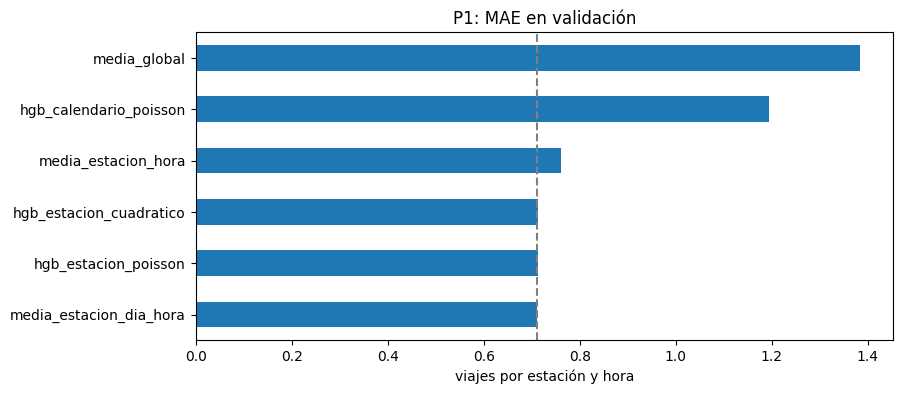

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
summary["val_mae"].sort_values().plot(kind="barh", ax=ax, title="P1: MAE en validación")
ax.axvline(summary.loc["media_estacion_dia_hora", "val_mae"], color="grey", linestyle="--")
ax.set_xlabel("viajes por estación y hora")
plt.savefig(C.FIGURES / "p1_exploracion_modelos_final.png", dpi=120, bbox_inches="tight")

> **Candidato: HistGradientBoosting con calendario y codificación de estación.**
> - La propuesta no codificaba la estación porque los rezagos ya traían su nivel. Sin rezagos, con solo calendario el modelo no sabe de qué estación se trata y queda muy por encima del baseline.
> - Se le agrega la media de train por estación y por estación-día-hora con `TargetEncoder`, que usa validación cruzada dentro de train: ninguna fila ve su propio objetivo y no entra ningún día reservado.
> - Se usa la configuración de la propuesta: pérdida Poisson, que es la natural para conteos, con 100 iteraciones. El error cuadrático da casi lo mismo, así que no hay razón para cambiarla.

> **Resultado honesto.** Sin rezagos, toda la información disponible es calendario y estación, que es justo lo que resume el baseline. El candidato no lo mejora en validación y la regla conserva el baseline. Mejorar P1 requiere la actividad reciente de cada estación (rezagos) con una partición temporal; queda como siguiente iteración.

## Decisión

| | Elección |
|---|---|
| Baseline | Media de train por estación, día y hora |
| Candidato | `TargetEncoder` (estación y estación-día-hora) + `HistGradientBoostingRegressor(loss="poisson", learning_rate=0.1, max_iter=100, max_leaf_nodes=31, random_state=39)` |
| Variables | Calendario de `features.py` |
| Regla | Se queda el candidato solo si baja `val_mae`; prueba se mide una vez en MLflow |